# Colab 1 — Bayesian vs classical Bernoulli models
## Titanic survival by passenger class

**Original notebook covered:** `6_1_PyMC_bayesian_analysis_coins` (Beta–Bernoulli, MCMC, Bayes factors, posterior predictive, hierarchical shrinkage, WAIC).

**This notebook uses a different dataset:** seaborn `titanic` — each passenger either survived (`1`) or did not (`0`). Passenger class plays the role of “which coin.”

**Classical counterparts** come from `2_Scipy_stats` (bootstrap, binomial / χ² / Fisher tests, confidence intervals) and sit next to the Bayesian answers.

**Assignment format.** Every **Lecture question** below is copied from the lecturer's notebooks (`6_1`, plus the scipy-stats / statsmodels prompts used in the comparison). Each is followed by a written answer. Basic programming (context managers as syntax, `curl`) is omitted; the statistical content of those prompts is answered.

Run top to bottom in Google Colab. Sampling is modest (about 1–2 minutes on CPU).



In [1]:
# Colab setup — run once
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install pymc arviz graphviz
    !apt-get -qq install -y graphviz > /dev/null
print("Ready. Runtime → Change runtime type → CPU is enough.")



Ready. Runtime → Change runtime type → CPU is enough.


In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import arviz as az
import pymc as pm

az.style.use("arviz-darkgrid")
np.random.seed(42)
rng = np.random.default_rng(42)


def show_model(model):
    """Draw the PyMC DAG; fall back to text if graphviz is missing."""
    try:
        g = pm.model_to_graphviz(model)
        try:
            from IPython.display import display
            display(g)
        except Exception:
            print(g)
    except Exception as exc:
        print("graphviz not available:", exc)
        print(model)



## 1. Data

We keep passengers with a known class and survival outcome. Class 1 / 2 / 3 are three groups that share a “mint” (the same ship, same disaster) but are not identical.



In [3]:
raw = sns.load_dataset("titanic")
df = (
    raw[["survived", "pclass", "sex", "age"]]
    .dropna(subset=["survived", "pclass"])
    .copy()
)
df["survived"] = df["survived"].astype(int)
df["pclass"] = df["pclass"].astype(int)
df["class_name"] = df["pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})

print(df.shape)
display(df.head())
print("\nSurvival by class:")
display(
    df.groupby("class_name")["survived"]
    .agg(n="size", survivors="sum", rate="mean")
    .reindex(["1st", "2nd", "3rd"])
)



(891, 5)


,survived,pclass,sex,age,class_name
0,0,3,male,22.0,3rd
1,1,1,female,38.0,1st
2,1,3,female,26.0,3rd
3,1,1,female,35.0,1st
4,0,3,male,35.0,3rd



Survival by class:


,n,survivors,rate
class_name,,,
1st,216,136,0.629630
2nd,184,87,0.472826
3rd,491,119,0.242363


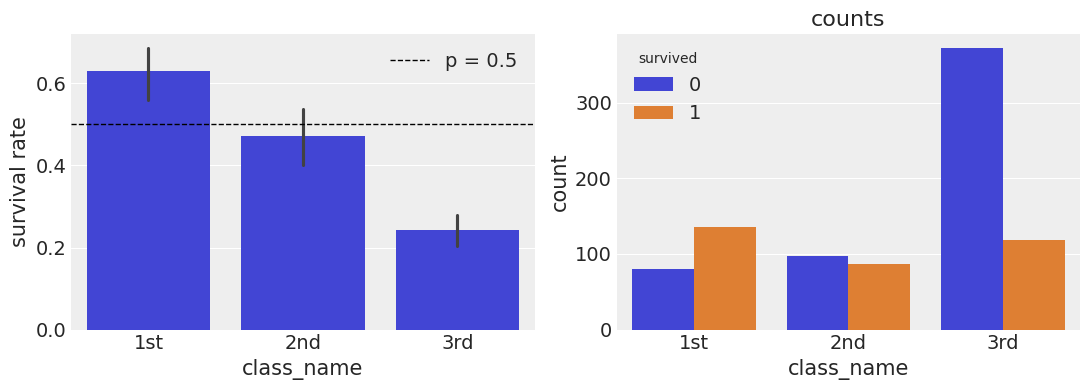

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="class_name", y="survived", order=["1st", "2nd", "3rd"], ax=axes[0], errorbar=("ci", 95))
axes[0].axhline(0.5, color="k", ls="--", lw=1, label="p = 0.5")
axes[0].set_ylabel("survival rate")
axes[0].legend()
sns.countplot(data=df, x="class_name", hue="survived", order=["1st", "2nd", "3rd"], ax=axes[1])
axes[1].set_title("counts")
plt.tight_layout()
plt.show()



## 2. One proportion: is overall survival 50%?

Treat every passenger as a Bernoulli trial with unknown $p$.

### Classical answer (`scipy.stats`)

Point estimate $\hat p = \bar y$. By the CLT, $\hat p$ is approximately Normal, so we can form a Wald interval. Bootstrap does the same job without the Normal story. A binomial test asks $H_0: p = 0.5$ directly.



In [5]:
y_all = df["survived"].to_numpy()
n_all = len(y_all)
p_hat = y_all.mean()
print(f"n = {n_all},  p_hat = {p_hat:.4f}")

# Wald (Normal) and t intervals — same tools as the scipy-stats notebook
wald = stats.norm.interval(0.95, loc=p_hat, scale=np.sqrt(p_hat * (1 - p_hat) / n_all))
t_ci = stats.t.interval(0.95, df=n_all - 1, loc=p_hat, scale=y_all.std(ddof=1) / np.sqrt(n_all))
boot = stats.bootstrap((y_all,), np.mean, confidence_level=0.95, random_state=42)

print("Wald 95% CI:     ", wald)
print("t 95% CI:        ", t_ci)
print("bootstrap 95% CI:", (boot.confidence_interval.low, boot.confidence_interval.high))

binom = stats.binomtest(int(y_all.sum()), n=n_all, p=0.5)
print("\nBinomial test H0: p = 0.5")
print(binom)



n = 891,  p_hat = 0.3838
Wald 95% CI:      (np.float64(0.3519060427032577), np.float64(0.4157707249735099))
t 95% CI:         (np.float64(0.3518445989680297), np.float64(0.4158321687087379))
bootstrap 95% CI: (np.float64(0.35241301907968575), np.float64(0.4163860830527497))

Binomial test H0: p = 0.5
BinomTestResult(k=342, n=891, alternative='two-sided', statistic=0.3838383838383838, pvalue=4.150727789853727e-12)


---

**Lecture question**

Discuss the differences between Bayesian and frequentist stats. Use an example of estimating the bias of a coin.

From scipy-stats: What are confidence intervals and confidence levels? What's the relation between confidence levels and p-values? How do I calculate a parametric CI? Mention the normal and t distributions. What are the underlying assumptions?

Explain how the bootstrap method works. Mention sampling from the ECDF. Compare it to regular parameter estimation. How do you calculate CIs with the bootstrap?

**Answer**

**Frequentist.** The survival probability $p$ is an unknown constant. The data $Y_1,\ldots,Y_n$ are iid $\mathrm{Bernoulli}(p)$ — they are random. Probability statements are about the *procedure* under repeated sampling. $\hat{p}=\bar{Y}$ is random. A 95% Wald interval

$$\hat{p} \pm z_{0.975}\sqrt{\hat{p}(1-\hat{p})/n}$$

covers the true $p$ in 95% of hypothetical replays of the same experiment. After we observe $\hat{p}$, it is not valid to say $P(p\in\mathrm{CI}\mid\mathrm{data})=0.95$. A p-value for $H_0\colon p=0.5$ is $P(\text{data as or more extreme}\mid H_0)$, not $P(H_0\mid\mathrm{data})$. Duality: a 95% CI is essentially the set of null values not rejected by a 5% test.

Parametric CIs need a sampling model. The Normal interval uses the CLT $\hat{p}\approx N\bigl(p,\,p(1-p)/n\bigr)$ (requires $np$ and $n(1-p)$ not tiny). The $t_{n-1}$ interval with $s/\sqrt{n}$ is the Gaussian-*mean* interval; using it for a Bernoulli mean is a common but inexact hack. `binomtest` inverts the exact binomial tail and is the honest frequentist test for one proportion.

**Bootstrap.** The ECDF $\mathbb{F}_n$ is a nonparametric MLE of $F$. Drawing $Y^*$ iid from $\mathbb{F}_n$ (here: resampling 0/1 with replacement) mimics drawing from $F$. A percentile CI takes the 2.5% and 97.5% quantiles of $\hat{p}^*$. It avoids a Normal approximation but still assumes the original sample is iid from $F$. Titanic passengers are a convenience census of one ship, so both Wald and bootstrap intervals are model-based stories, not magic.

**Bayesian.** $p$ is given a prior $\pi(p)$ on $(0,1)$. Bayes' theorem yields

$$\pi(p\mid y)\propto L(y\mid p)\,\pi(p).$$

A 94% credible set $I$ satisfies $P(p\in I\mid y)=0.94$. With a flat prior and large $n$, $\mathrm{Beta}(1+\sum y_i,\,1+n-\sum y_i)$ sits close to the Wald interval. That numerical agreement is not a theorem that the philosophies coincide: a $\mathrm{Beta}(20,20)$ prior (strong belief in 50-50) moves the posterior; the Wald interval does not.

**Critical point.** Frequentist coverage is a pre-data property of a random interval. Bayesian probability is a post-data property of $p$. Applied papers constantly swap those sentences.



### Bayesian answer

1. $p$ is a random variable.
2. Before seeing data we only know $0 \le p \le 1$, so a uniform prior is $Beta(1,1)$.
3. Bernoulli likelihood + Beta prior ⇒ Beta posterior (conjugate). We still use MCMC so the workflow matches the non-conjugate models later.

**Why Beta?** It is supported on $(0,1)$ and is conjugate to Bernoulli / Binomial, so the posterior stays in the same family. That is the “natural” prior for a coin (or a survival probability).



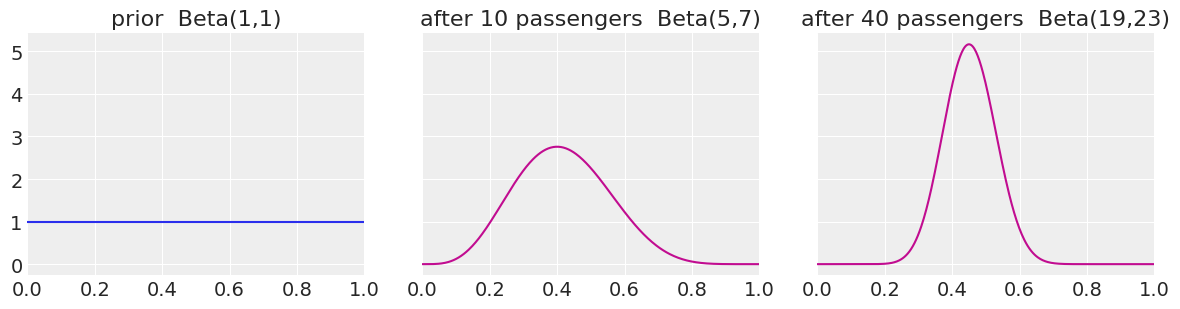

analytic posterior after 40 observations: mean = 0.452


In [6]:
x_grid = np.linspace(0, 1, 400)

def plot_beta(a, b, ax=None, **kwargs):
    ax = ax or plt.gca()
    ax.plot(x_grid, stats.beta.pdf(x_grid, a, b), **kwargs)
    ax.set_xlim(0, 1)

# sequential Bayesian update on a small random subsample (illustration)
sub = rng.choice(y_all, size=40, replace=False)
a, b = 1.0, 1.0
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
plot_beta(a, b, axes[0], color="C0")
axes[0].set_title("prior  Beta(1,1)")
for i, yi in enumerate(sub, start=1):
    a += yi
    b += 1 - yi
    if i in (10, 40):
        ax = axes[1 if i == 10 else 2]
        plot_beta(a, b, ax, color="C3")
        ax.set_title(f"after {i} passengers  Beta({a:.0f},{b:.0f})")
plt.tight_layout()
plt.show()
print("analytic posterior after 40 observations: "
      f"mean = {a / (a + b):.3f}")



---

**Lecture question**

Why is a Beta the natural choice for a prior in this case?

**Answer**

A parameter $p\in(0,1)$ needs a prior supported on $(0,1)$. The Beta family has that support, is flexible (U-shaped, flat, unimodal), and is **conjugate** to Bernoulli/Binomial:
$$
\mathrm{Beta}(\alpha,\beta)\;+\;s\text{ successes in }n\text{ trials}
\;\Rightarrow\;
\mathrm{Beta}(\alpha+s,\beta+n-s).
$$
Conjugacy is computational convenience, not a scientific law. It is "natural" because the sufficient statistic $(s,n)$ updates the prior as if $\alpha-1$ and $\beta-1$ were pseudo-counts, and because $\mathrm{Beta}(1,1)=\mathrm{Uniform}(0,1)$ matches the lecture's "I know only the range" start.

**Criticism.** Uniform on $p$ is not uniform on $\mathrm{logit}(p)$. Jeffreys' prior is $\mathrm{Beta}(1/2,1/2)$, which piles mass near 0 and 1. For Titanic overall, $n\approx 800$, so $\mathrm{Beta}(1,1)$ vs $\mathrm{Beta}(1/2,1/2)$ will not change a decision. For a class of 12 passengers it would. "Uninformative" is not unique; always name the Beta.



## 3. The same model in PyMC

$P(\text{data})$ is almost never available in closed form. MCMC draws from the posterior without computing that constant. Here the closed form exists; MCMC is still useful as a check and as the method we will keep using when conjugacy dies.



Output()

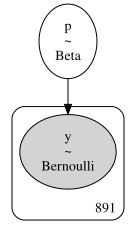

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [7]:
with pm.Model() as betabin:
    p = pm.Beta("p", alpha=1.0, beta=1.0)
    pm.Bernoulli("y", p=p, observed=y_all)
    idata = pm.sample(1000, chains=4, tune=1000, random_seed=42, progressbar=True)

show_model(betabin)
idata



---

**Lecture question**

1. What's MCMC? How can we use it to estimate the posterior without calculating P(data)?
2. Is there any reason to use MCMC when the closed form is known?
3. My prof said MCMC is the worst sampling algorithm available, but the only one that does the job. What's your take?

Explain the output of `pm.sample()`. (Context-manager syntax omitted as basic programming.)

**Answer**

**MCMC.** Markov chain Monte Carlo constructs $\theta^{(t)}$ whose invariant distribution is $\pi(\theta\mid y)$. After warmup, averages of $f(\theta^{(t)})$ estimate $\mathbb{E}[f(\theta)\mid y]$. The chain never needs $p(y)=\int L(y\mid\theta)\pi(\theta)\,d\theta$. Metropolis–Hastings uses the ratio
$$
\frac{\pi(\theta'\mid y)}{\pi(\theta\mid y)}=\frac{L(y\mid\theta')\pi(\theta')}{L(y\mid\theta)\pi(\theta)},
$$
in which $p(y)$ cancels.

**Closed form known.** Still use MCMC to keep one codebase for the next non-conjugate model; to get predictives, HDIs, and WAIC from the same object; and as a check that conjugate arithmetic matches the sampler (mean should equal $\alpha/(\alpha+\beta)$). Cost: Monte Carlo error and the possibility of silent sampling failure.

**"Worst algorithm that works."** Independent draws from the exact Beta dominate MCMC here (inverse-CDF). MCMC is the least-bad *general* posterior sampler when no generator exists. HMC/NUTS is much better than random-walk Metropolis, and still fails on discrete parameters, multi-modality, and funnels (notebook 2).

**`pm.sample()`.** An ArviZ `InferenceData`: `posterior` (draws by chain), `sample_stats` (divergences, tree depth, energy), `observed_data`, later `posterior_predictive` and `log_likelihood`. Multiple chains exist so $\hat R$ has something to disagree about if mixing failed.



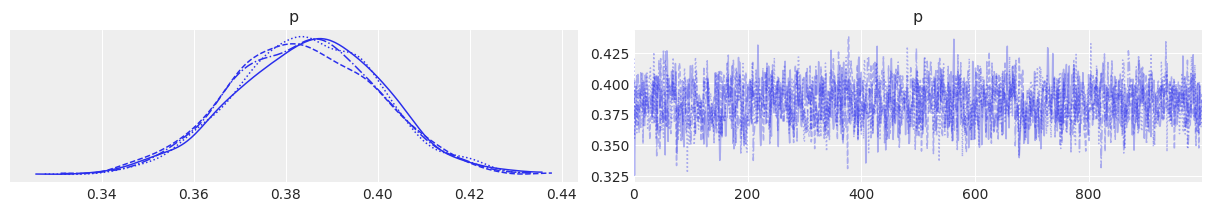

In [8]:
az.plot_trace(idata)
plt.show()



---

**Lecture question**

What do you think about these trace plots?

**Answer**

On this conjugate Beta–Bernoulli with hundreds of observations, NUTS should look *boring*: KDEs from all chains stacked, traces like white noise around $\hat p$, no stickiness, no trend, no chain stranded away from the others. Boredom is the goal.

Separated humps by chain mean the sampler has not found one posterior ($\hat R$ will scream). A slow random walk on the right means tiny ESS and noisy HDIs. Critical habit: do not quote `az.summary` until the trace is boring. Pretty numbers from a broken chain are not inference.



### Credible intervals vs confidence intervals

A 94% **HDI** (highest-density interval) is the shortest interval that contains 94% of the posterior mass. A **central** credible interval uses equal tails (3% each). A frequentist 95% CI is a random interval that covers the true $p$ in 95% of repeated samples — it is not $P(p \in \text{CI} \mid \text{data})$.



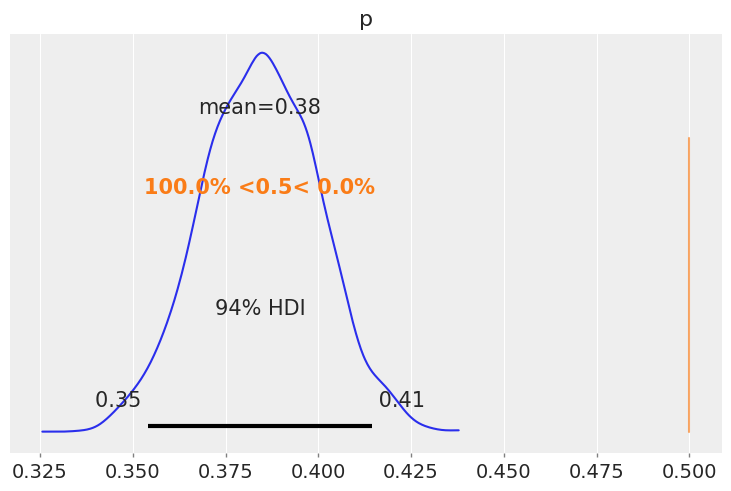

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p,0.384,0.016,0.354,0.414,0.0,0.0,1557.0,2775.0,1.0


In [9]:
az.plot_posterior(idata, ref_val=0.5)
plt.show()
display(az.summary(idata, hdi_prob=0.94))



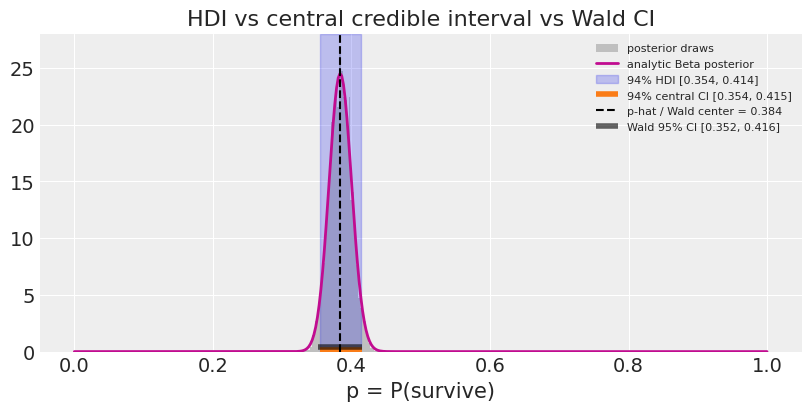

In [10]:
post_p = idata.posterior["p"].values.reshape(-1)
hdi = az.hdi(post_p, hdi_prob=0.94)
# equal-tail (central) 94% credible interval
central = np.quantile(post_p, [0.03, 0.97])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(post_p, bins=40, density=True, color="0.75", label="posterior draws")
ax.plot(x_grid, stats.beta.pdf(x_grid, 1 + y_all.sum(), 1 + n_all - y_all.sum()),
        color="C3", lw=2, label="analytic Beta posterior")
ax.axvspan(*hdi, color="C0", alpha=0.25, label=f"94% HDI [{hdi[0]:.3f}, {hdi[1]:.3f}]")
ax.plot(central, [0.15, 0.15], color="C1", lw=4, solid_capstyle="butt",
        label=f"94% central CI [{central[0]:.3f}, {central[1]:.3f}]")
ax.axvline(p_hat, color="k", ls="--", label=f"p-hat / Wald center = {p_hat:.3f}")
ax.plot(wald, [0.4, 0.4], color="k", lw=4, alpha=0.6, solid_capstyle="butt",
        label=f"Wald 95% CI [{wald[0]:.3f}, {wald[1]:.3f}]")
ax.set_xlabel("p = P(survive)")
ax.set_title("HDI vs central credible interval vs Wald CI")
ax.legend(fontsize=8)
plt.show()



---

**Lecture question**

What's HDI? Compare to frequentist confidence intervals.
What about other credible intervals?
Draw a figure illustrating the difference between central credible intervals and HDIs. (The figure is the cell above.)

**Answer**

The **highest-density interval** of level $1-\alpha$ is the shortest set $I$ with posterior mass $1-\alpha$. For a unimodal density it is $\{\theta: \pi(\theta\mid y) \ge k\}$ for a cutoff $k$ chosen to hit the probability. A **central** (equal-tail) interval uses the $\alpha/2$ and $1-\alpha/2$ quantiles instead. They coincide for symmetric unimodal posteriors and diverge for skewed ones (small $n$, $p$ near 0 or 1): the HDI then sits closer to the mode and can exclude a long tail that the central interval includes.

A frequentist CI is a *random* interval with a coverage guarantee before seeing data. It is not a probability statement about $p$ given $y$. Numerically, with a flat prior and large $n$, Wald and HDI can look alike; that is an asymptotic accident, not a definitional identity.

**Other credible sets.** HPDs in 2-D can be disconnected; quantile intervals are easier to report. One-sided credible bounds exist analogously to one-sided CIs. Decision-theoretically, the HDI is the Bayes estimator of a set under a 0–1 loss that penalizes length — that is why we prefer it when we want "where the posterior actually lives."

**Criticism of both.** An HDI with a silly prior is a precise answer to the wrong question. A 95% CI that excludes 0.5 can coexist with a posterior that still puts 20% of its mass above 0.5 if the prior is skeptical. Always plot the posterior; do not reduce it to one interval.



The HDI and the central interval almost agree here because the posterior is nearly symmetric. They disagree when the posterior is skewed (small $n$, $p$ near 0 or 1). The Wald interval is a sampling-theory object; numerically it can sit close to the Bayesian interval under a flat prior and large $n$.

### Hypothesis testing: Bayes factor vs binomial p-value

`az.plot_bf` uses the **Savage–Dickey density ratio** for nested point-null tests:

$$
\mathrm{BF}_{01} = \frac{p(\theta = \theta_0 \mid \text{data})}{p(\theta = \theta_0)}
$$

Here $H_0: p = 0.5$ and $H_1: p \neq 0.5$ with a uniform prior. The prior density at 0.5 is 1; the posterior density at 0.5 is estimated from the MCMC draws. $\mathrm{BF}_{01} \gg 1$ favors $H_0$; $\mathrm{BF}_{10} = 1/\mathrm{BF}_{01}$ favors $H_1$.

Rough Jeffreys scale for $\mathrm{BF}_{10}$: ~1–3 weak, 3–10 moderate, 10–30 strong, $>100$ decisive. Do not treat it as a posterior probability of $H_0$, and do not use it blindly for non-nested models (use WAIC / LOO).



The reference value is outside of the posterior. This translate into infinite support for H1, which is most likely an overstatement.


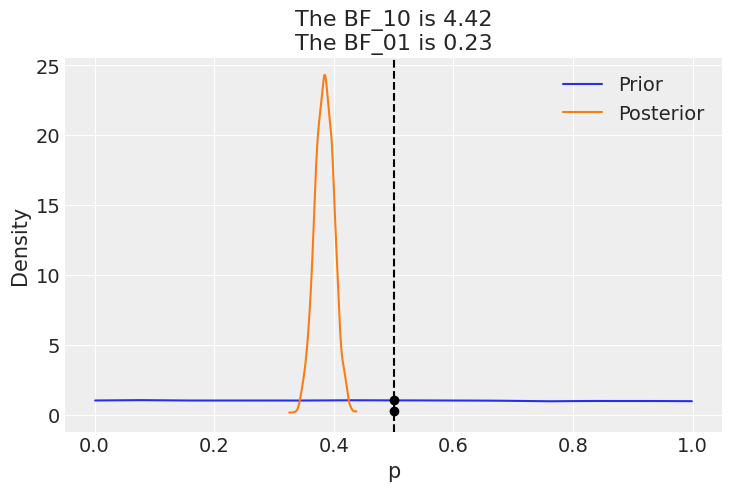

Frequentist counterpart: binomial test p-value = 4.150727789853727e-12


In [11]:
try:
    az.plot_bf(idata, var_name="p", prior=np.random.uniform(0, 1, 10_000), ref_val=0.5)
    plt.show()
except Exception as exc:
    print("az.plot_bf unavailable (", exc, ") — Savage–Dickey by KDE")
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(post_p)
    bf01 = float(kde(0.5) / 1.0)  # uniform prior density = 1
    print(f"BF01 (H0: p=0.5) ≈ {bf01:.3f}   BF10 ≈ {1 / bf01:.3f}")
print("Frequentist counterpart: binomial test p-value =", binom.pvalue)



---

**Lecture question**

1. What's the Bayes factor? Compare it to the frequentist counterpart in hypothesis testing.
2. `az.plot_bf(..., ref_val=0.5)` — What's H0 and H1? How does ArviZ calculate the BF? Mention the Savage–Dickey density ratio and why it is valid.
3. How should I interpret the BF? Give a scale.
4. Can I use the BF to test more elaborate hypotheses? What are the pitfalls?

**Answer**

The **Bayes factor** comparing $H_0$ to $H_1$ is the ratio of marginal likelihoods
$$
\mathrm{BF}_{01}=\frac{p(y\mid H_0)}{p(y\mid H_1)}=\frac{\int L(y\mid\theta,H_0)\pi(\theta\mid H_0)\,d\theta}{\int L(y\mid\theta,H_1)\pi(\theta\mid H_1)\,d\theta}.
$$
It is the factor that turns prior odds into posterior odds. The frequentist counterpart is a likelihood-ratio test or a p-value: both ask how surprising the data are *under $H_0$*, not how the two models predict relative to each other. A tiny p-value can coexist with $\mathrm{BF}_{01}\approx 1$ in large samples (Lindley's paradox): the test rejects a point null that the Bayes factor still finds more predictive than a vague alternative.

**This call.** $H_0: p=0.5$ (a point null nested in $H_1: p\in(0,1)$ with prior Uniform). ArviZ uses **Savage–Dickey**: for a nested point null,
$$
\mathrm{BF}_{01}=\frac{\pi(p=0.5\mid y)}{\pi(p=0.5)}.
$$
Validity: under $H_1$ the prior on $p$ is absolutely continuous; the posterior density at the nested point, divided by the prior density there, equals the marginal-likelihood ratio. Intuition: if data *deplete* the density at 0.5 relative to the prior, $H_0$ looks worse.

**Jeffreys-style $\mathrm{BF}_{10}=1/\mathrm{BF}_{01}$:** ~1–3 anecdotal, 3–10 moderate, 10–30 strong, 30–100 very strong, $>100$ decisive. These are conventions, not calibrated Type I errors. Report the number and the prior.

**Elaborate hypotheses / pitfalls.** Interval hypotheses ($p<0.4$) need the full marginal likelihood, not Savage–Dickey at a point. Non-nested models (independent vs hierarchical coins) should not be compared by a point-null BF; use WAIC/LOO or a proper bridge-sampling BF. Savage–Dickey is unstable if the posterior density at $\theta_0$ is estimated from few MCMC draws in the tail. BFs are extremely prior-sensitive: a tighter alternative prior changes $\mathrm{BF}_{01}$ even if the posterior barely moves. Do not treat $\mathrm{BF}_{10}>3$ as 'the effect exists'.



### Bayes estimators (point summaries of the posterior)

A **point estimate** is any single number. A **Bayes estimator** is the number that minimises expected posterior loss.

| loss | Bayes estimator |
|---|---|
| squared error $L_2$ | posterior mean |
| absolute error $L_1$ | posterior median |
| 0–1 (tiny window) | posterior mode (MAP) |

Use the mean for reporting a rate, the median if you want robustness to a long tail, the mode if a downstream rule must pick the most probable value (e.g. a classification threshold).



L2 minimizer / posterior mean:   0.38345864661654133 0.3842898650534048
L1 minimizer / posterior median: 0.38345864661654133 0.38438063530895455


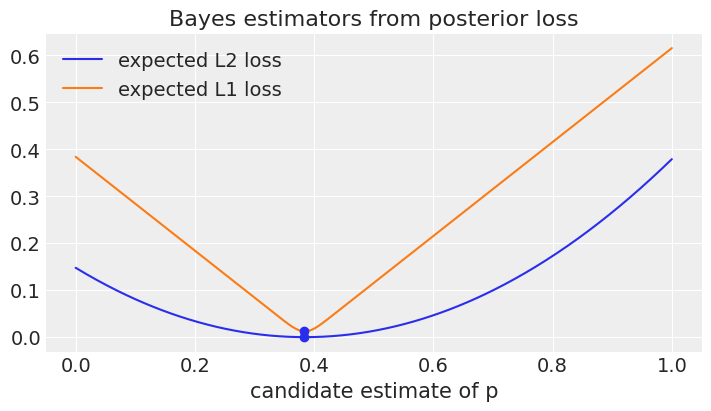

In [12]:
post = post_p
L2 = np.mean((post[:, None] - x_grid[None, :]) ** 2, axis=0)
L1 = np.mean(np.abs(post[:, None] - x_grid[None, :]), axis=0)
print("L2 minimizer / posterior mean:  ", x_grid[L2.argmin()], post.mean())
print("L1 minimizer / posterior median:", x_grid[L1.argmin()], np.median(post))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_grid, L2, label="expected L2 loss")
ax.plot(x_grid, L1, label="expected L1 loss")
ax.scatter(x_grid[[L2.argmin(), L1.argmin()]], [L2.min(), L1.min()], zorder=3)
ax.set_xlabel("candidate estimate of p")
ax.set_title("Bayes estimators from posterior loss")
ax.legend()
plt.show()



---

**Lecture question**

1. I'm doing Bayesian inference. Is there any use case where I would need a point estimate for a parameter?
2. What's the difference between a point estimate and a Bayes estimator?
3. What are the common Bayes estimators and the relevant loss functions?
4. Give a real-life scenario in which one of mean / median / mode is the clear choice.

**Answer**

Point summaries are needed whenever a downstream action requires a number: a published survival rate, a threshold in a protocol, a plug-in for a later frequentist procedure, or a decision (order $n$ lifeboats). The full posterior is better, but institutions demand scalars.

A **point estimate** is any scalar $\hat\theta(y)$. A **Bayes estimator** is a point estimate that minimises expected posterior loss $\mathbb{E}[L(\theta,a)\mid y]$. Same number, extra justification.

| loss $L(\theta,a)$ | minimiser |
|---|---|
| $(\theta-a)^2$ | posterior mean |
| $\lvert\theta-a\rvert$ | posterior median |
| $1\{\lvert\theta-a\rvert>\varepsilon\}$ as $\varepsilon\to 0$ | posterior mode (MAP) |

**Scenario.** Mean: report "expected fraction who survive" for an insurance premium (squared-error / $L_2$ matches averaging money). Median: set a survival probability for a communication that should not be yanked by a long right tail. Mode: if a discrete action is "treat $p$ as the most probable value" (MAP classification, or a regulator that only cares whether the most likely $p$ exceeds 0.5). For Titanic overall the three almost coincide; for a 12-person subgroup they need not.

**Criticism.** Publishing only a posterior mean hides the fact that $P(p>0.5\mid y)$ may still be 0.15. Loss functions are ethical choices: $L_2$ over-penalises being wrong about rare events in the tail.



## 4. Posterior predictive

The **posterior** is uncertainty in $p$. The **posterior predictive** is uncertainty in a *new* Bernoulli outcome:

$$
p(\tilde y \mid y) = \int p(\tilde y \mid p)\, p(p \mid y)\, dp
$$

That mixture is a Beta–Binomial. Drawing it is not a new MCMC run: take a posterior draw of $p$, then simulate Bernoulli($p$). Sampling a binomial given $p$ is inverse-CDF / coin-flip simulation, not Metropolis.



Output()

('chain', 'draw', 'y_dim_0')
one replicated survival vector, first 20: [1 1 1 0 1 0 1 1 0 0 0 0 0 1 0 0 1 0 1 0]
observed rate:      0.3838383838383838
PPC mean rate:      0.3842932098765432
PPC 94% HDI for the rate: [0.34006734 0.42536476]


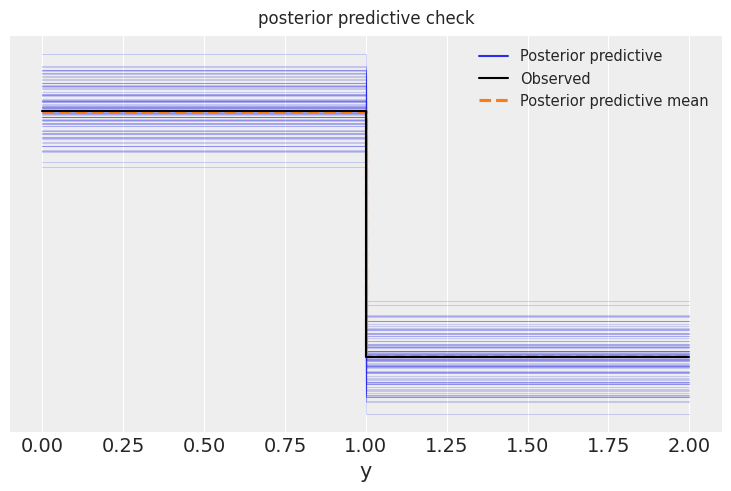

In [13]:
with betabin:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=42)

ppc = idata.posterior_predictive["y"]
print(ppc.dims)
obs_dim = [d for d in ppc.dims if d not in ("chain", "draw")][0]
print("one replicated survival vector, first 20:", ppc.isel(chain=0, draw=0).values[:20])
print("observed rate:     ", y_all.mean())
print("PPC mean rate:     ", float(ppc.mean()))
rate_draws = ppc.mean(dim=obs_dim).values.reshape(-1)
print("PPC 94% HDI for the rate:", az.hdi(rate_draws, hdi_prob=0.94))

try:
    az.plot_ppc(idata, num_pp_samples=100)
    plt.suptitle("posterior predictive check")
    plt.show()
except Exception as exc:
    print("plot_ppc skipped:", exc)
    obs_dim = [d for d in ppc.dims if d not in ("chain", "draw")][0]
    rates = ppc.mean(dim=obs_dim).values.reshape(-1)
    plt.hist(rates, bins=30, color="0.7")
    plt.axvline(y_all.mean(), color="C3")
    plt.xlabel("replicated survival rate")
    plt.show()



---

**Lecture question**

1. What's the difference between a posterior and a posterior predictive? Use the coin-tossing example and mention the Beta–Binomial.
2. How would I sample from the Beta–Binomial? Is this MCMC? How would I sample a binomial?

**Answer**

The **posterior** $\pi(p\mid y)$ is uncertainty about the *parameter*. The **posterior predictive** $p(\tilde y\mid y)=\int p(\tilde y\mid p)\,\pi(p\mid y)\,dp$ is uncertainty about a *new observation*. For Beta–Bernoulli, conjugacy gives a Beta–Binomial: if $p\sim\mathrm{Beta}(\alpha,\beta)$ posterior and $\tilde y\mid p\sim\mathrm{Bin}(m,p)$, then
$$
p(\tilde y=k\mid y)=\binom{m}{k}\frac{B(\alpha+k,\beta+m-k)}{B(\alpha,\beta)}.
$$
The posterior interval for $p$ shrinks like $1/\sqrt{n}$; the predictive interval for a *single* new passenger stays order-1 wide (Bernoulli variance $p(1-p)$). Confusing the two is how people claim "we know survival to ±1%" and then act as if the *next* passenger is deterministic.

**Sampling.** Not a new MCMC: draw $p^{(s)}$ from the already-computed posterior (or from the analytic Beta), then draw $\tilde y^{(s)}\sim\mathrm{Bernoulli}(p^{(s)})$ or $\mathrm{Bin}(m,p^{(s)})$. A binomial given $p$ is inverse-transform / repeated Bernoulli; libraries use optimized generators. MCMC was only used to obtain $\{p^{(s)}\}$ when we refused the closed form.



## 5. Many classes — independent model

Questions we can now ask:

- Is the *ship* fair on average? (pool everyone — we just did)
- Is *each class* at 50%?
- Is 1st class more survival-biased than 3rd?
- Is the “mint” (the ship) biased? That last one needs a hierarchical model.

First, an **independent** model: each class has its own $p_c \sim Beta(1,1)$, no sharing.



In [14]:
class_names = np.array(["1st", "2nd", "3rd"])
df["class_idx"] = df["class_name"].map({n: i for i, n in enumerate(class_names)}).astype(int)

y = df["survived"].to_numpy()
idx = df["class_idx"].to_numpy()
print("n per class:", np.bincount(idx))
print("rate per class:", df.groupby("class_idx")["survived"].mean().to_numpy())



n per class: [216 184 491]
rate per class: [0.62962963 0.47282609 0.24236253]


Output()

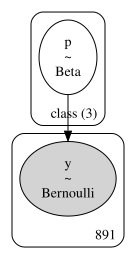

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p[1st],0.628,0.032,0.568,0.688,0.001,0.001,2637.0,1297.0,1.0
p[2nd],0.473,0.036,0.405,0.541,0.001,0.001,3087.0,1551.0,1.0
p[3rd],0.244,0.019,0.206,0.279,0.000,0.001,3059.0,1356.0,1.0


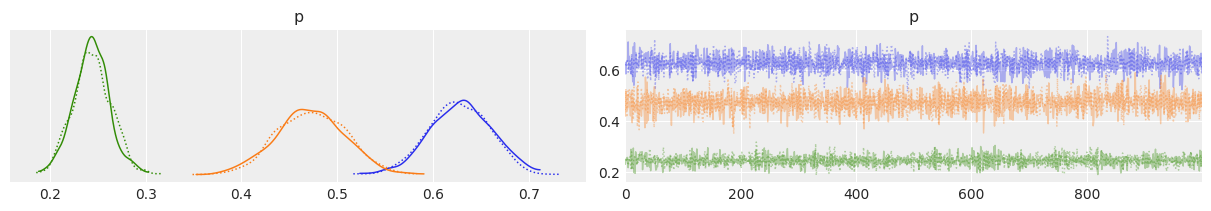

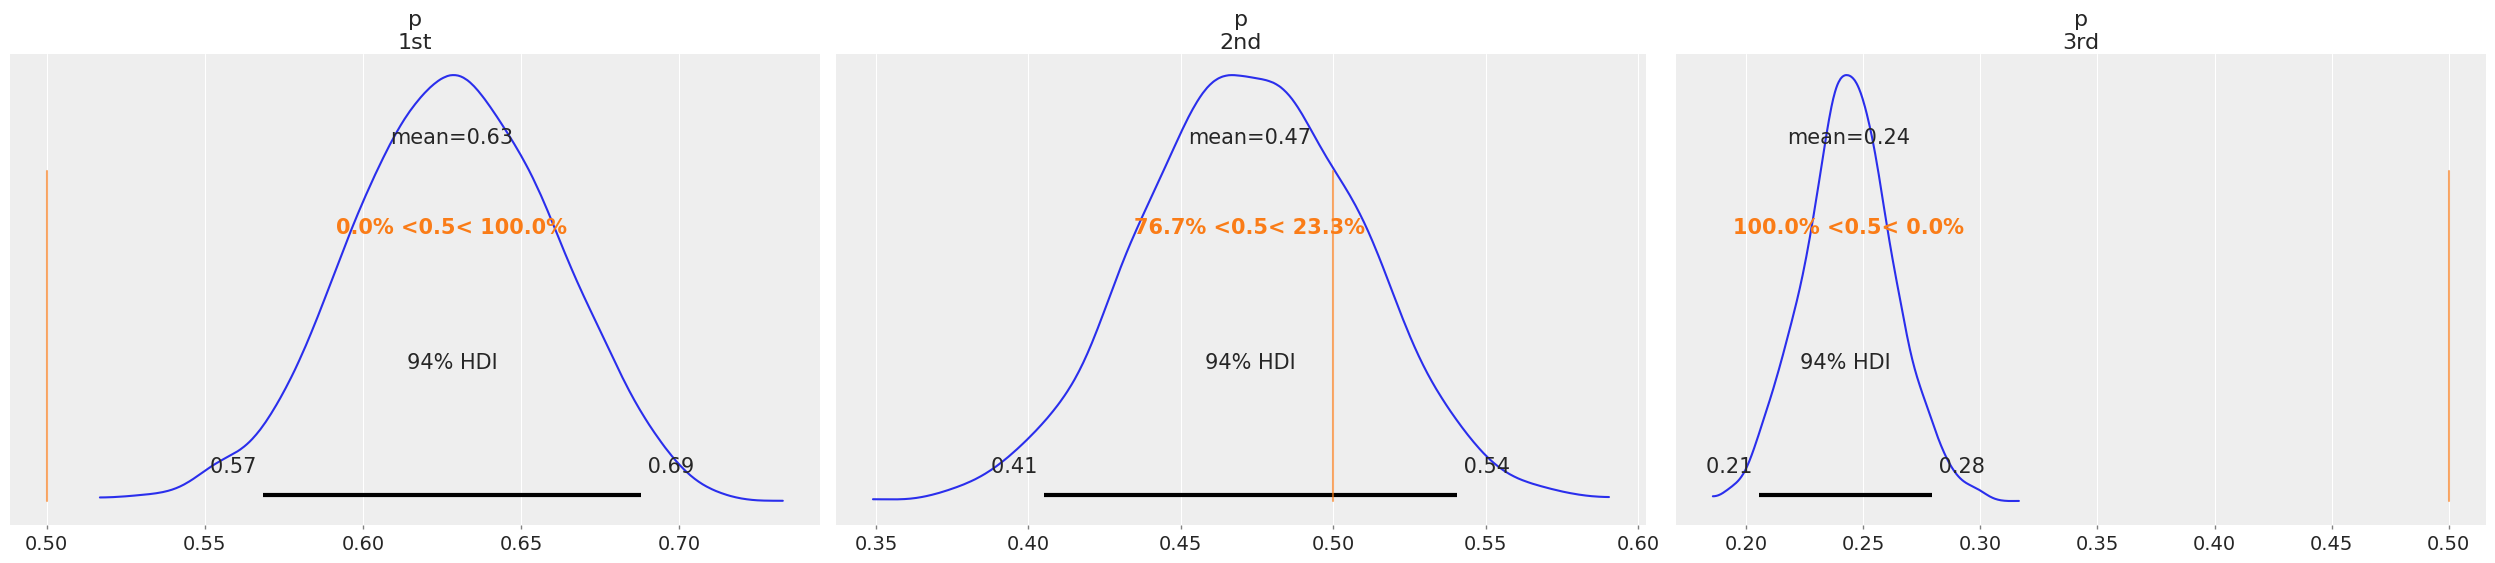

In [15]:
coords = {"class": class_names}
with pm.Model(coords=coords) as betabin_vec:
    p = pm.Beta("p", alpha=1.0, beta=1.0, dims="class")
    pm.Bernoulli("y", p=p[idx], observed=y)
    idata_vec = pm.sample(
        1000, chains=2, tune=1000, random_seed=42,
        idata_kwargs={"log_likelihood": True},
    )
show_model(betabin_vec)
display(az.summary(idata_vec))
az.plot_trace(idata_vec)
plt.show()
az.plot_posterior(idata_vec, ref_val=0.5)
plt.show()



`idx = class_idx` is the standard PyMC indexing trick: one parameter vector `p` of length 3, and observation $i$ uses `p[idx[i]]`. That is the same idea as `np.unravel_index` in the coin notebook — a flat outcome vector plus a group label.

### Classical side-by-side for the three classes

Independence across classes is also the χ² / Fisher story: a 3×2 table of class × survived.



In [16]:
ctab = pd.crosstab(df["class_name"], df["survived"])
display(ctab)
print("chi2 contingency:\n", stats.chi2_contingency(ctab))

# pairwise 1st vs 3rd: Fisher (small cells are fine) and a two-proportion z via chi2 on the 2x2
ctab_13 = pd.crosstab(df.loc[df["pclass"].isin([1, 3]), "class_name"],
                      df.loc[df["pclass"].isin([1, 3]), "survived"])
print("\n1st vs 3rd Fisher exact:", stats.fisher_exact(ctab_13))
print("1st vs 3rd chi2:", stats.chi2_contingency(ctab_13))



survived,0,1
class_name,,
1st,80,136
2nd,97,87
3rd,372,119


chi2 contingency:
 Chi2ContingencyResult(statistic=np.float64(102.88898875696056), pvalue=np.float64(4.549251711298793e-23), dof=2, expected_freq=array([[133.09090909,  82.90909091],
       [113.37373737,  70.62626263],
       [302.53535354, 188.46464646]]))

1st vs 3rd Fisher exact: SignificanceResult(statistic=np.float64(0.1881720430107527), pvalue=np.float64(1.7869561685835935e-22))
1st vs 3rd chi2: Chi2ContingencyResult(statistic=np.float64(95.89348388920357), pvalue=np.float64(1.2123375217498223e-22), dof=1, expected_freq=array([[138.09335219,  77.90664781],
       [313.90664781, 177.09335219]]))


---

**Lecture question**

From scipy-stats (used here as the classical comparison):
What's the test statistic in Fisher's exact test? How do we calculate the p-value?
Why are the marginals in Fisher's exact test fixed? When should I prefer another test?
What's an odds ratio?
What are the assumptions of the chi-squared test? What's H0?

(The lecture's `unravel_index` line is indexing: one flat Bernoulli vector plus a group label so `p[idx[i]]` picks the class-specific rate. That is the statistical model, not a programming puzzle.)

**Answer**

**Fisher exact.** For a $2\times 2$ table with *fixed* row and column totals, the count in one cell is Hypergeometric. The p-value is the sum of hypergeometric probabilities of tables at least as extreme (usually in the odds-ratio sense). Marginals are fixed because the thought experiment is: the number of 1st-class passengers and the number of survivors are given; only the *assignment* of survivors to classes is random. That matches some designed experiments (lady tasting tea: 10 milk-first cups, 10 guesses). It is questionable for Titanic: class sizes are given, but the total number of survivors is an outcome, not a design constraint. Then the table is not truly hypergeometric and Fisher is conservative.

**Odds ratio.** $\mathrm{OR}=\frac{p_1/(1-p_1)}{p_3/(1-p_3)}$. Fisher tests $H_0:\mathrm{OR}=1$. An OR of 3 is not "three times as likely to survive" (that would be a risk ratio). With common events (Titanic 1st class), OR and RR diverge.

**Chi-squared.** $H_0$: independence of class and survival, i.e. $p_{c,1}=p_c\cdot p_{\cdot 1}$. Statistic $\sum (O-E)^2/E$ with $E$ from the product of margins. Assumptions: independent observations, large expected counts (rule of thumb $E\ge 5$). Violated expected counts → p-value from the $\chi^2$ approximation is wrong; use Fisher or a Monte Carlo chi-squared. Titanic 3×2 is large enough for chi-squared; 1st vs 3rd is also fine. Do not use chi-squared on the same table you already peeked at in ten other tests without a multiplicity plan.

**Vs Bayesian.** Fisher/chi-squared answer "is there any association?" The hierarchical model answers "how different are the $p_c$, and should a small class borrow strength?" A significant chi-squared does not tell you the size of the 1st–3rd gap; the posterior of $p_1-p_3$ does.



## 6. Hierarchical model

Assumption: classes come from the same disaster — not independent. We put a prior on the *distribution of class rates*.

Two Beta parameterizations:

- $Beta(\alpha, \beta)$: $\alpha$ prior successes, $\beta$ prior failures.
- $Beta(\mu, \nu)$: $\mu = \mathbb{E}[p]$, $\nu \approx$ prior sample size. $\mathrm{Var}(p) = \mu(1-\mu)/(\nu+1)$, so large $\nu$ means classes are similar.

**Hyperpriors:** $\mu \sim Beta(2,2)$ is a soft preference for rates away from 0/1 but still covers the unit interval. $\nu \sim HalfNormal(30)$ says “maybe a few dozen prior observations of similarity, not thousands.”



Output()

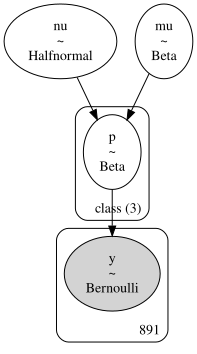

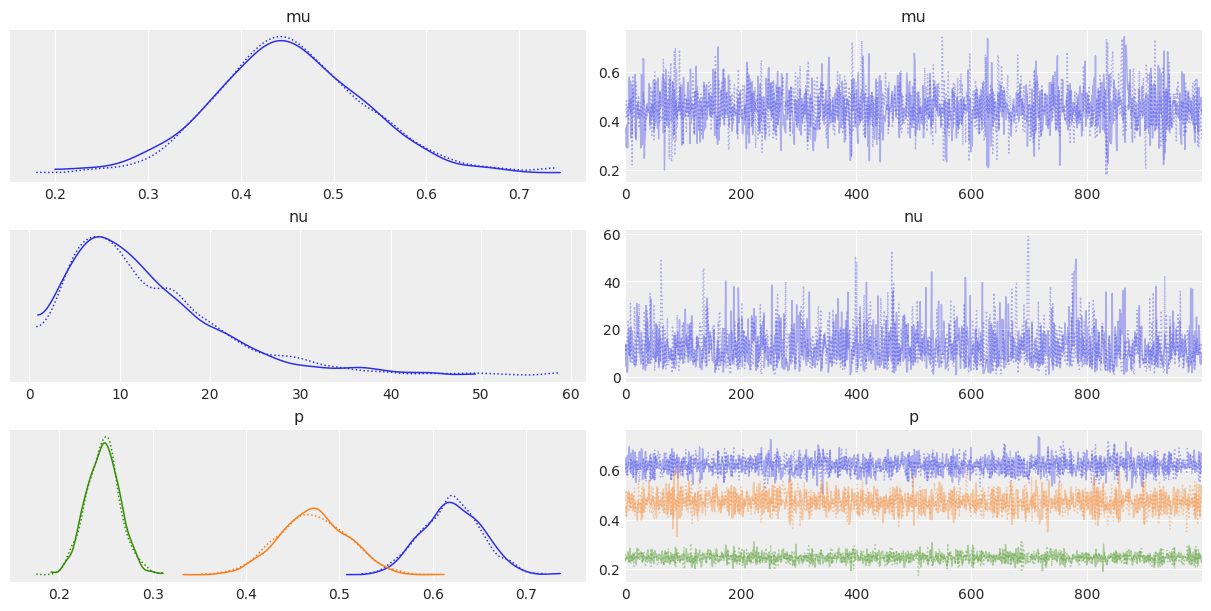

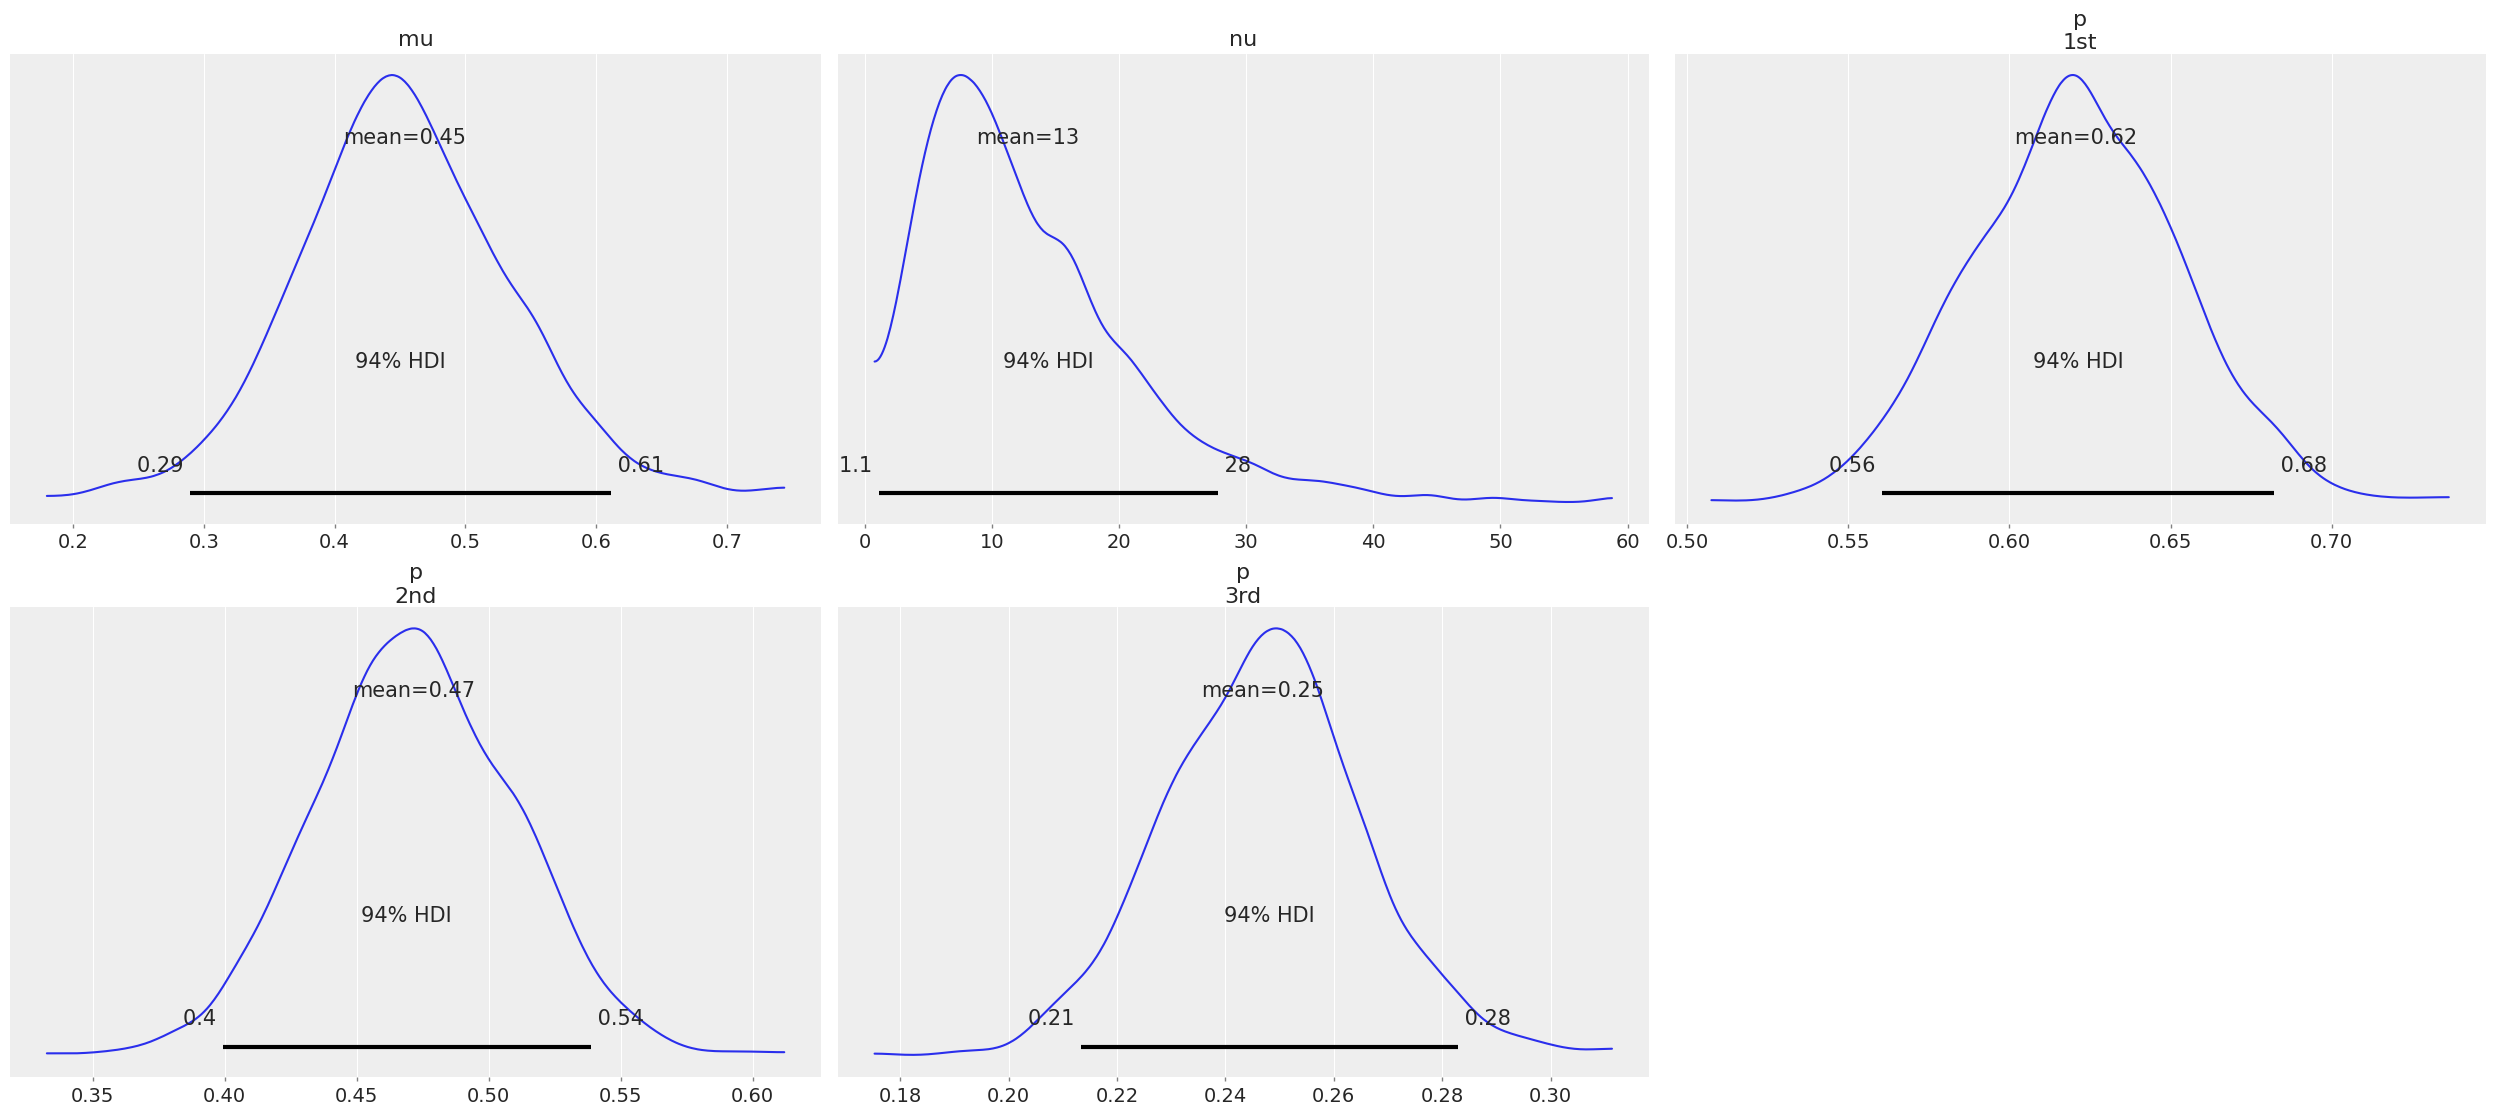

In [17]:
with pm.Model(coords=coords) as betabin_h:
    mu = pm.Beta("mu", 2.0, 2.0)          # E[p] across classes
    nu = pm.HalfNormal("nu", sigma=30)    # concentration ≈ 1/std
    p = pm.Beta("p", mu=mu, nu=nu, dims="class")
    pm.Bernoulli("y", p=p[idx], observed=y)
    idata_h = pm.sample(
        1000, chains=2, tune=1000, random_seed=42, target_accept=0.9,
        idata_kwargs={"log_likelihood": True},
    )
show_model(betabin_h)
az.plot_trace(idata_h)
plt.show()
az.plot_posterior(idata_h)
plt.show()



---

**Lecture question**

1. Are hierarchical Bayesian models popular as a modelling tool? Why?
2. Compare Beta($\alpha,\beta$) vs Beta($\mu,\nu$). What do the parameters mean? How is $\nu$ related to $\mathrm{Var}[X]$?
3. What's a hyperprior?
4. Why is `mu = pm.Beta('mu', 2, 2)`, `nu = pm.HalfNormal('nu', 30)` a reasonable hyperprior? Discuss both the family and the numbers.

**Answer**

They are popular because they encode **partial pooling**: groups are neither identical (complete pooling) nor unrelated (no pooling). That is the default scientific state — Titanic classes share a disaster but not a survival probability. Hierarchies also give honest uncertainty for small groups and a posterior for the population scatter $\nu$.

**Parameterizations.** $\alpha,\beta>0$: $\mathbb{E}[p]=\alpha/(\alpha+\beta)$, $\mathrm{Var}(p)=\alpha\beta/[(\alpha+\beta)^2(\alpha+\beta+1)]$. $\mu=\alpha/(\alpha+\beta)\in(0,1)$, $\nu=\alpha+\beta>0$ (prior sample size / concentration). Then $\mathrm{Var}(p)=\mu(1-\mu)/(\nu+1)$. Large $\nu$ ⇒ classes look similar; $\nu\to 0$ recovers independent $U(0,1)$-like rates. The $(\mu,\nu)$ form is the right language for "typical rate" vs "how much classes differ."

A **hyperprior** is a prior on the parameters of a prior. Here $\mu,\nu$ govern the distribution of class-level $p_c$; they are not observed. Without a hyperprior you would have to *fix* $\mu,\nu$ (empirical Bayes point estimate) and understate uncertainty.

**This choice.** $\mathrm{Beta}(2,2)$ on $\mu$ is a soft mound on 0.5, down-weighting $\mu\approx 0$ or $1$ (a ship where *every* class has survival 0.01 is a priori odd) but still allows those values. $\mathrm{HalfNormal}(30)$ on $\nu$ says concentrations of tens, not thousands: we expect noticeable class differences, not almost-identical rates. If we set $\nu\sim\mathrm{HalfNormal}(1000)$ we would over-shrink 3rd class toward 1st. If $\nu$ were given a prior with mass at 0, we would allow a no-pooling limit and might need a non-centered parameterization (notebook 2).

**Criticism.** Three classes are a very small "sample of groups" from which to learn $\nu$. The hyperposterior on $\nu$ will be prior-sensitive. That is not a reason to drop the hierarchy; it is a reason not to over-interpret $\hat\nu$.



### Shrinkage

Hierarchical models pull noisy group estimates toward the grand mean. That *is* partial pooling / empirical-Bayes shrinkage. It helps small groups; it can over-shrink if groups are truly heterogeneous (the “mint” assumption is wrong) or if one group is an outlier the hyperprior cannot see.

To make shrinkage visible we **thin 3rd class** down to 12 passengers and refit both models.



thinned n per class: [216 184  12]
thinned rates:       [np.float64(0.6296296296296297), np.float64(0.47282608695652173), np.float64(0.08333333333333333)]


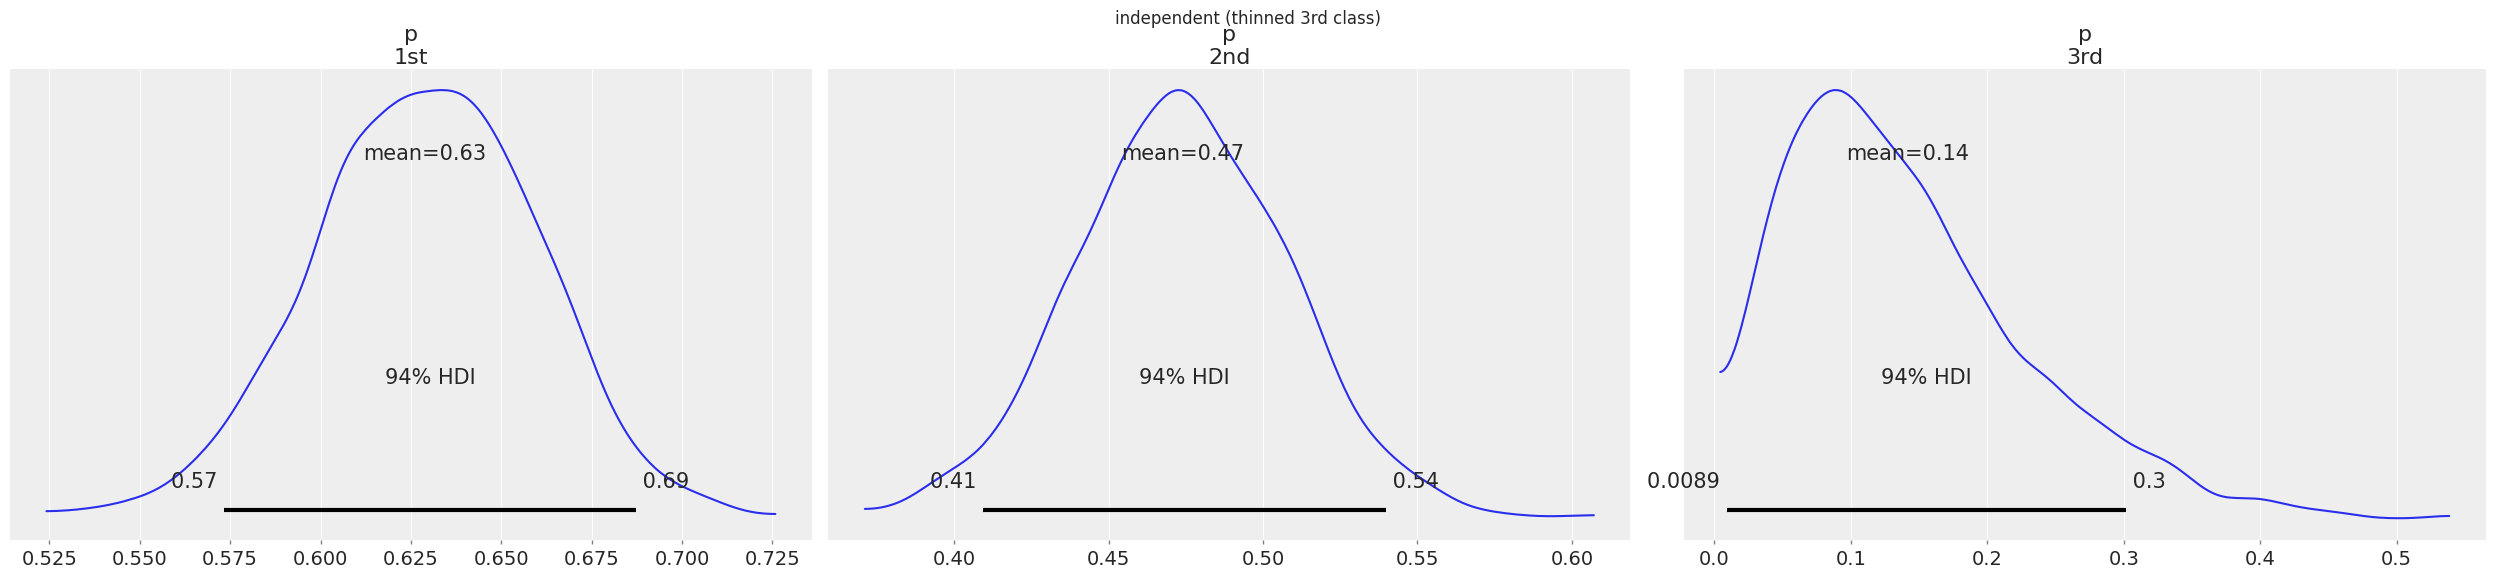

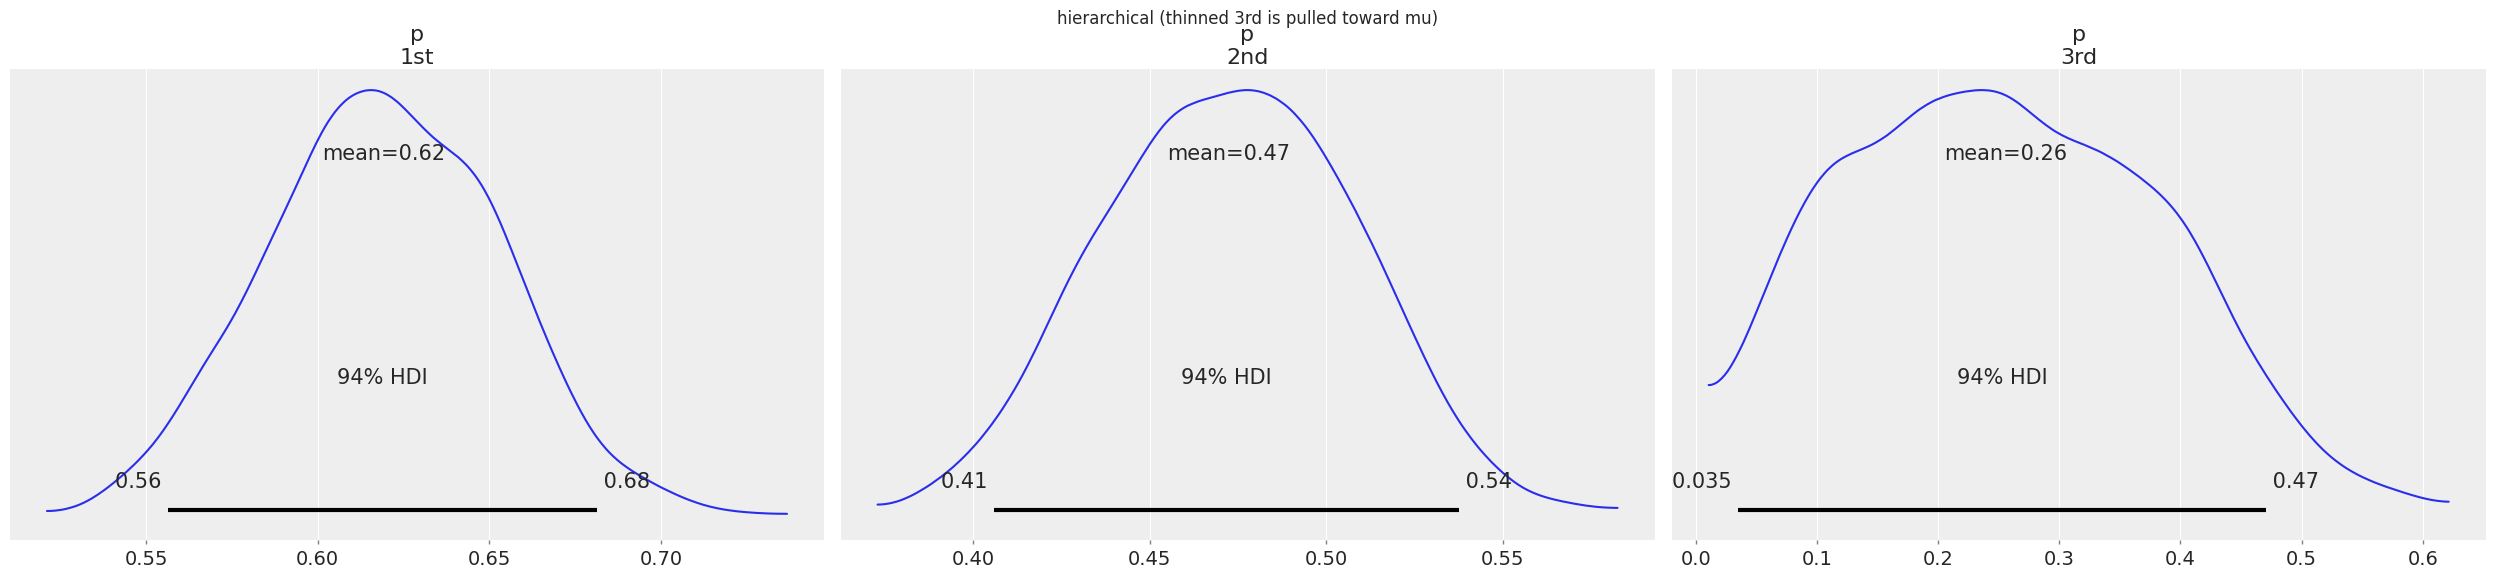

,independent,hierarchical,raw rate
1st,0.628954,0.619194,0.629630
2nd,0.473876,0.472357,0.472826
3rd,0.141377,0.255848,0.083333


In [18]:
thin = df.copy()
keep_3rd = thin.loc[thin["class_idx"] == 2].sample(12, random_state=0)
thin = pd.concat([thin.loc[thin["class_idx"] != 2], keep_3rd], ignore_index=True)
y_t = thin["survived"].to_numpy()
idx_t = thin["class_idx"].to_numpy()
print("thinned n per class:", np.bincount(idx_t))
print("thinned rates:      ", [y_t[idx_t == k].mean() for k in range(3)])

with pm.Model(coords=coords) as m_ind_thin:
    p = pm.Beta("p", 1, 1, dims="class")
    pm.Bernoulli("y", p=p[idx_t], observed=y_t)
    id_ind_thin = pm.sample(800, chains=2, tune=800, random_seed=1, progressbar=False)

with pm.Model(coords=coords) as m_h_thin:
    mu = pm.Beta("mu", 2, 2)
    nu = pm.HalfNormal("nu", 30)
    p = pm.Beta("p", mu=mu, nu=nu, dims="class")
    pm.Bernoulli("y", p=p[idx_t], observed=y_t)
    id_h_thin = pm.sample(800, chains=2, tune=800, random_seed=1, target_accept=0.9, progressbar=False)

az.plot_posterior(id_ind_thin, var_names=["p"])
plt.suptitle("independent (thinned 3rd class)", y=1.02)
plt.show()
az.plot_posterior(id_h_thin, var_names=["p"])
plt.suptitle("hierarchical (thinned 3rd is pulled toward mu)", y=1.02)
plt.show()

cmp_thin = pd.DataFrame({
    "independent": id_ind_thin.posterior["p"].mean(("chain", "draw")).values,
    "hierarchical": id_h_thin.posterior["p"].mean(("chain", "draw")).values,
    "raw rate": [y_t[idx_t == k].mean() for k in range(3)],
}, index=class_names)
display(cmp_thin)



---

**Lecture question**

Compare the independent vs hierarchical results. What's shrinkage? Do I know it by another name? How is shrinkage built into hierarchical models? Show common failure modes of shrinkage.

**Answer**

After thinning 3rd class to 12 passengers, the independent posterior for $p_3$ is wide and glued to the raw rate. The hierarchical posterior for $p_3$ moves toward $\mu$ (the estimated typical class rate) and is narrower. 1st class barely moves because it has a lot of data.

**Shrinkage** is that pull toward the grand mean. Other names: partial pooling, Stein shrinkage, empirical Bayes, "borrowing strength." James–Stein showed that shrinking independent Gaussian means toward the grand mean dominates the MLE in MSE for $k\ge 3$ dimensions — the same geometry.

It is built in because $p_c\mid\mu,\nu\sim\mathrm{Beta}(\mu,\nu)$ *a priori* ties the $p_c$ together. The posterior mean of $p_c$ is a precision-weighted average of the group MLE and $\mu$. Small $n_c$ ⇒ more weight on $\mu$.

**Failure modes.** (1) **Overshrinkage / "mint" false:** classes are not exchangeable (crew vs passengers, or a truly different ship). Then 3rd class is pulled toward a mean it should not share. (2) **Simpson / confounding:** pooling on the wrong grouping. (3) **Outlier group:** one class is a different mechanism; a Gaussian/Beta hierarchy without a heavy tail shrinks it too hard (use a $t$ hyperprior or a mixture). (4) **Few groups:** $\nu$ unidentified, shrinkage amount driven by the hyperprior you picked. (5) **Ecological fallacy:** interpreting $\mu$ as "the passenger-level probability."

The plot is the argument: if independent and hierarchical $p_3$ disagree a lot, either 3rd class is small (good shrinkage) or the hierarchy is misspecified (bad shrinkage). Domain knowledge — class *should* matter on the Titanic — warns against complete pooling, not against partial pooling.



## 7. Model comparison — WAIC

WAIC is a Bayesian analogue of AIC: out-of-sample predictive accuracy with a penalty on effective number of parameters. Hierarchical and independent models are **not nested** in the $p=0.5$ sense, so a Savage–Dickey Bayes factor is the wrong tool. BIC is a Laplace approximation to a marginal likelihood under a specific prior; it is used, but WAIC / LOO are the default in this stack.

A larger (less negative) ELPD is better. `p_waic` is the effective parameter count — hierarchical models often look “smaller” than independent ones because shrinkage reduces effective flexibility.



,rank,elpd_waic,p_waic,elpd_diff,weight,se,dse,warning,scale
independent,0,-544.538290,2.979959,0.000000,0.5,11.606938,0.000000,False,log
hierarchical,1,-544.539184,2.919953,0.000894,0.5,11.386948,0.277738,False,log


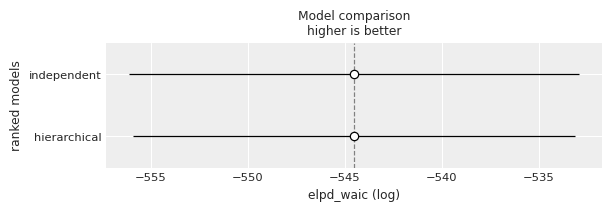

In [19]:
for name, idat, model in [("ind", idata_vec, betabin_vec), ("h", idata_h, betabin_h)]:
    if "log_likelihood" not in idat:
        with model:
            pm.compute_log_likelihood(idat)
cmp_df = az.compare({"independent": idata_vec, "hierarchical": idata_h}, ic="waic")
display(cmp_df)
az.plot_compare(cmp_df)
plt.show()



---

**Lecture question**

1. I have two Bayesian models (non-nested). How do I choose?
2. Are the independent and hierarchical coin/class models nested? Can I use the BF? WAIC?
3. Explain the WAIC table. Why do we measure "effective" number of parameters?
4. Does one use BIC with Bayesian models in general?

**Answer**

Non-nested Bayesian models are compared by **predictive criteria** (WAIC, LOO-CV) or by a properly computed Bayes factor (bridge sampling / nested sampling), not by a point-null Savage–Dickey ratio.

The independent model is $p_c\sim_{\mathrm{iid}}\mathrm{Beta}(1,1)$. The hierarchical model is $p_c\mid\mu,\nu\sim\mathrm{Beta}(\mu,\nu)$ with priors on $\mu,\nu$. They are **not nested** in the $H_0:p=0.5$ sense (neither is a point restriction of the other). A BF is theoretically defined but painful and prior-sensitive; WAIC is the lecture's tool.

**WAIC** estimates expected log pointwise predictive density with a penalty $p_{\mathrm{waic}}$ equal to the posterior variance of the log-likelihood, summed over observations. That $p_{\mathrm{waic}}$ is the **effective** number of parameters: shrinkage makes a hierarchical model with 3 $p_c$ plus $\mu,\nu$ behave as if it had *fewer* free parameters than 3 independent $p_c$. If $p_{\mathrm{waic}}$ is huge or `warning=True`, the approximation is bad (often influential points); then use LOO and look at Pareto-$k$.

Read `elpd_waic` (higher / less negative is better) and `elpd_diff` vs `se`. A difference smaller than the SE is not a decision. On Titanic, with three large classes, WAIC may barely prefer either model — that is an honest answer, not a failure.

**BIC.** $\mathrm{BIC}=-2\log\hat L + k\log n$ is a Laplace approximation to $-2\log p(y)$ under a specific prior and a well-identified interior MLE. People do use it on Bayesian models, but it does not use the actual prior you wrote in PyMC, it counts $k$ as integer parameters (ignoring shrinkage), and it is not the ELPD. Prefer WAIC/LOO for the models we fit here; use a real marginal likelihood if the decision is "which model is true," not "which predicts new passengers."

**Criticism.** WAIC can prefer a model that is scientifically wrong but flexible. Class as the grouping is a causal story, not a predictive contest. If WAIC picks independent and you believe in a shared disaster, report both.



## 8. Takeaways

| question | classical | Bayesian |
|---|---|---|
| overall $p$ | $\hat p$, Wald / bootstrap CI, binomial test | Beta–Bernoulli, HDI, Savage–Dickey BF |
| class differences | χ², Fisher exact | independent $p_c$ plus pairwise posterior contrasts |
| small class | unstable $\hat p$ | hierarchical shrinkage toward $\mu$ |
| which model? | AIC / likelihood ratio (nested) | WAIC / LOO (need not be nested) |

**When MCMC is still worth it with a closed-form posterior:** same code path as the next model, easy posterior predictive, easy change of prior, automatic HDI / BF / WAIC.

Next notebook: the same Bayesian-vs-OLS comparison for regression, plus MCMC diagnostics.

